# Exploratory Data Analysis (EDA)
## KNN Movie Recommendation System

### Objective
Explore the MovieLens dataset to understand genre distribution,
multiple genres per movie, repeated movie titles, and release-year patterns.

This notebook builds on the initial dataset inspection completed in Task 2.
The original dataset will remain unchanged.

In [1]:
import pandas as pd

movies = pd.read_csv("../data/ml-latest-small/movies.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", movies.shape)
print("Column names:", movies.columns.tolist())
movies[["title", "genres"]].head(10)

Dataset loaded successfully!
Dataset shape: (9742, 3)
Column names: ['movieId', 'title', 'genres']


,title,genres
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy
2,Grumpier Old Men (1995),Comedy|Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance
4,Father of the Bride Part II (1995),Comedy
5,Heat (1995),Action|Crime|Thriller
6,Sabrina (1995),Comedy|Romance
7,Tom and Huck (1995),Adventure|Children
8,Sudden Death (1995),Action
9,GoldenEye (1995),Action|Adventure|Thriller


In [2]:
# Split each movie's genre string into individual genres
genre_lists = movies["genres"].str.split("|")

# Convert the lists into a single Series of genre labels
all_genres = genre_lists.explode()

# Count how many movies are associated with each genre
genre_counts = all_genres.value_counts()

# Display the 20 most frequent genre labels
print(genre_counts.head(20))

genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


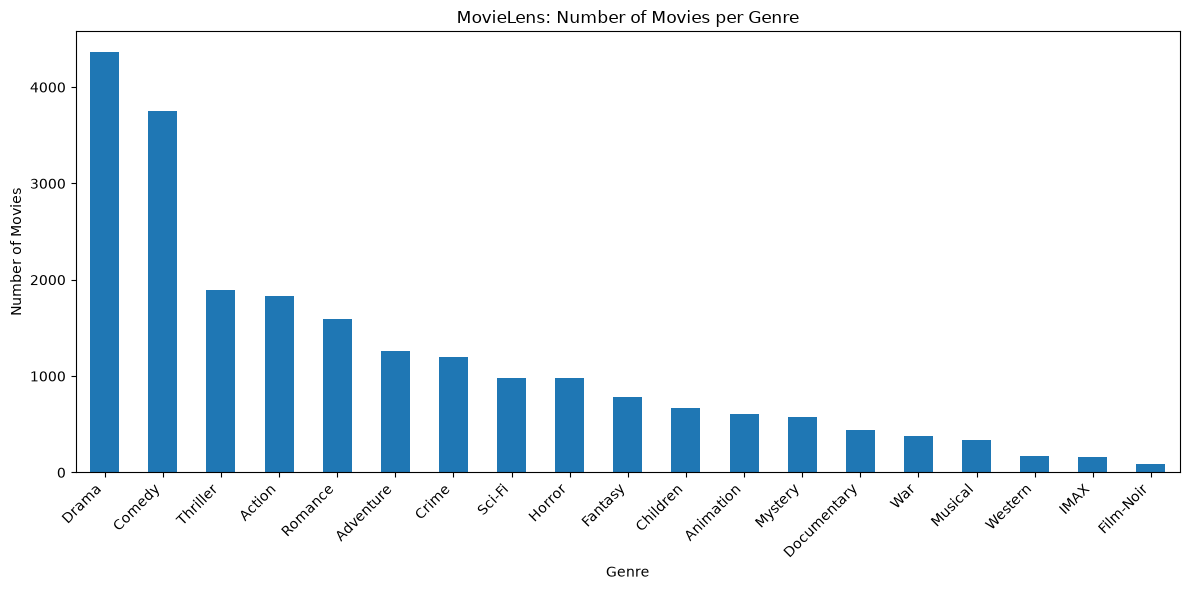

In [3]:
import matplotlib.pyplot as plt

# Exclude the special label from the main genre chart
plot_genre_counts = genre_counts.drop("(no genres listed)", errors="ignore")

# Sort genres from most frequent to least frequent
plot_genre_counts = plot_genre_counts.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(12, 6))
plot_genre_counts.plot(kind="bar")

plt.title("MovieLens: Number of Movies per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [4]:
# Count the number of genre labels assigned to each movie
genre_counts_per_movie = movies["genres"].str.split("|").str.len()

# Calculate how many movies have each genre count
genre_count_distribution = genre_counts_per_movie.value_counts().sort_index()

print("Distribution of number of genres per movie:")
print(genre_count_distribution)

Distribution of number of genres per movie:
genres
1     2851
2     3218
3     2338
4      987
5      271
6       63
7       12
8        1
10       1
Name: count, dtype: int64


In [5]:
# Identify movies with 8 or more listed genre labels
unusual_genre_movies = movies.loc[
    genre_counts_per_movie >= 8,
    ["movieId", "title", "genres"]
].copy()

print(unusual_genre_movies.to_string(index=False))

 movieId                                                          title                                                                        genres
   26701 Patlabor: The Movie (Kidô keisatsu patorebâ: The Movie) (1989)                Action|Animation|Crime|Drama|Film-Noir|Mystery|Sci-Fi|Thriller
   81132                                                  Rubber (2010) Action|Adventure|Comedy|Crime|Drama|Film-Noir|Horror|Mystery|Thriller|Western


In [6]:
# Find titles that appear more than once
repeated_title_mask = movies["title"].duplicated(keep=False)

# Display all records associated with repeated titles
repeated_title_movies = movies.loc[
    repeated_title_mask,
    ["movieId", "title", "genres"]
].sort_values("title")

print(repeated_title_movies.to_string(index=False))

 movieId                                  title                              genres
    6003 Confessions of a Dangerous Mind (2002)         Comedy|Crime|Drama|Thriller
  144606 Confessions of a Dangerous Mind (2002) Comedy|Crime|Drama|Romance|Thriller
     838                            Emma (1996)                Comedy|Drama|Romance
   26958                            Emma (1996)                             Romance
   32600                            Eros (2004)                               Drama
  147002                            Eros (2004)                       Drama|Romance
    2851                        Saturn 3 (1980)           Adventure|Sci-Fi|Thriller
  168358                        Saturn 3 (1980)                     Sci-Fi|Thriller
   34048               War of the Worlds (2005)    Action|Adventure|Sci-Fi|Thriller
   64997               War of the Worlds (2005)                       Action|Sci-Fi


## Release-Year Analysis

In this section, we extract provisional release years from movie titles.
We will examine the distribution of parsed years and identify titles
whose release year cannot be extracted using our pattern.

The original title column will remain unchanged.


In [7]:
# Extract a four-digit year in parentheses at the end of a title
movies["parsed_year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")

# Convert extracted years to numeric values
movies["parsed_year"] = pd.to_numeric(
    movies["parsed_year"],
    errors="coerce"
)

# Summarize extraction results
print("Total movies:", len(movies))
print("Movies with a parsed year:", movies["parsed_year"].notna().sum())
print("Movies without a parsed year:", movies["parsed_year"].isna().sum())

print("Earliest parsed year:", movies["parsed_year"].min())
print("Latest parsed year:", movies["parsed_year"].max())

Total movies: 9742
Movies with a parsed year: 9729
Movies without a parsed year: 13
Earliest parsed year: 1902.0
Latest parsed year: 2018.0


In [8]:
# Display titles for which no year was extracted
unparsed_year_movies = movies.loc[
    movies["parsed_year"].isna(),
    ["movieId", "title", "genres"]
]

print("Movies without a parsed year:")
print(unparsed_year_movies.to_string(index=False))

Movies without a parsed year:
 movieId                                               title                 genres
   40697                                           Babylon 5                 Sci-Fi
  140956                                    Ready Player One Action|Sci-Fi|Thriller
  143410                                          Hyena Road     (no genres listed)
  147250 The Adventures of Sherlock Holmes and Doctor Watson     (no genres listed)
  149334                                   Nocturnal Animals         Drama|Thriller
  156605                                            Paterson     (no genres listed)
  162414                                           Moonlight                  Drama
  167570                                              The OA     (no genres listed)
  171495                                              Cosmos     (no genres listed)
  171631                             Maria Bamford: Old Baby     (no genres listed)
  171749                   Death Note: Desu nô

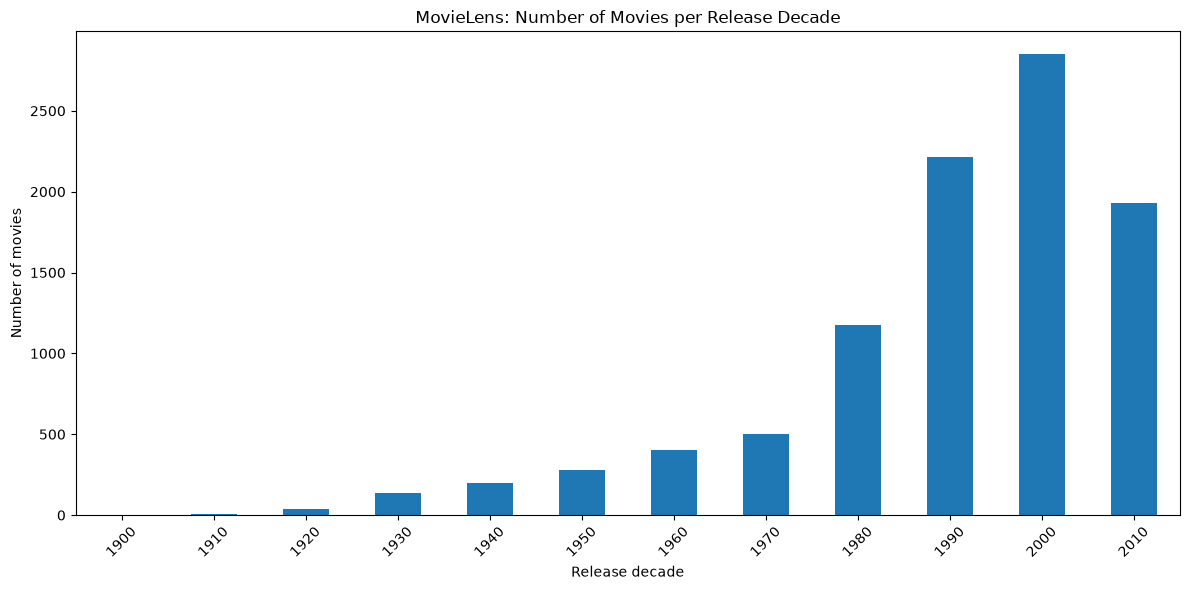

In [9]:
# Group movies with parsed years into decades
movies_with_year = movies.loc[movies["parsed_year"].notna()].copy()

movies_with_year["decade"] = (
    (movies_with_year["parsed_year"] // 10) * 10
).astype(int)

decade_counts = movies_with_year["decade"].value_counts().sort_index()

# Plot the number of movies per decade
plt.figure(figsize=(12, 6))
decade_counts.plot(kind="bar")

plt.title("MovieLens: Number of Movies per Release Decade")
plt.xlabel("Release decade")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## EDA Summary

### Objective
Explore the MovieLens dataset to understand its genre distribution,
genre counts per movie, repeated titles, and release-year patterns.

### 1. Genre Distribution


The dataset contains 9,742 movies and 3 columns.

- Drama is the most frequent genre, associated with 4,361 movies.
- Comedy is the second most frequent genre, associated with 3,756 movies.
- Film-Noir is the least frequent actual genre in the displayed results, associated with 87 movies.
- 34 movies have the special label `(no genres listed)`.
- Movies can belong to multiple genres, so genre frequencies can add up to more than the total number of movies.

**Interpretation:** Genre frequencies are unevenly distributed. Drama and Comedy appear much more frequently than Film-Noir. This may influence the genre overlap between movies in our planned recommendation system.

### 2. Number of Genres per Movie

The distribution of genre labels per movie was:

- 1 genre: 2,851 movies
- 2 genres: 3,218 movies
- 3 genres: 2,338 movies
- 4 genres: 987 movies
- 5 genres: 271 movies
- 6 genres: 63 movies
- 7 genres: 12 movies
- 8 genres: 1 movie
- 10 genres: 1 movie

Two genres was the most common count. One movie had eight genre labels, and another had ten.

**Interpretation:** Movies can have multiple genre features. This matters for KNN because movies sharing genre features may be considered similar, depending on the feature representation and distance metric.

The special label `(no genres listed)` was counted as one label in this analysis and will require a deliberate preprocessing decision later.

### 3. Repeated Movie Titles

Five titles appeared more than once, involving ten records.

The repeated titles were:
- Confessions of a Dangerous Mind (2002)
- Emma (1996)
- Eros (2004)
- Saturn 3 (1980)
- War of the Worlds (2005)

The records had different `movieId` values and different genre assignments.

**Interpretation:** A movie title alone may not uniquely identify a record. The recommendation system will need a deliberate strategy for handling repeated titles in a later task.

### 4. Release-Year Analysis

A year was extracted from 9,729 of the 9,742 movie titles.

- Movies with a parsed year: 9,729
- Movies without a parsed year: 13
- Earliest parsed year: 1902
- Latest parsed year: 2018

The extraction used a regular expression that looks for a four-digit year in parentheses at the end of a title. It did not match every title format, including a title containing a year range.

**Interpretation:** Unparsed years do not automatically mean invalid movies. The extracted years describe the titles that matched our pattern, and the original title column remains unchanged.

### 5. Implications for the KNN Recommendation System

1. **Genre features:** Genres provide content information that can represent each movie as a feature vector.

2. **Multiple genres:** A movie can have several genre features set to 1. Movies sharing genre features may be considered similar, depending on the chosen distance metric.

3. **Uneven genre frequencies:** Some genres occur much more frequently than others. We should examine how the feature representation and similarity metric affect recommendations.

4. **Missing genre information:** The `(no genres listed)` label requires a deliberate preprocessing decision. We should not silently discard these records during EDA.

5. **Repeated titles:** A title alone may not uniquely identify a movie. A reliable selection strategy will be needed later.

6. **Missing release years:** Movies without an extracted year should not automatically be excluded. The initial recommendation model will focus on genres, not release years.

7. **Recommendation quality:** EDA helps us understand the data, but recommendation quality must be evaluated separately after the model is built.

### 6. Limitations

- Release years were extracted using a specific title pattern, so some titles could not be parsed.
- Genre overlap does not guarantee that two movies are genuinely similar to viewers.
- The analysis describes the MovieLens dataset and should not be generalized to all movies.

### Conclusion

The EDA identified genre-frequency differences, multiple genres per movie, repeated titles, and limitations in release-year extraction. These findings will guide the preprocessing decisions in the next task. The original dataset has not been intentionally modified by this analysis.